In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler, OptionsV2 as Options, Session
from qiskit.transpiler import PassManager
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
#from qiskit.providers.fake_provider import FakeManila  # For optimization level
import numpy as np

In [2]:
def create_oracle(n_qubits, function_type='constant', constant_value=0):
    """
    Create an oracle for the Deutsch-Jozsa algorithm.
    
    Args:
        n_qubits (int): Number of input qubits
        function_type (str): 'constant' or 'balanced'
        constant_value (int): 0 or 1, used if function_type is 'constant'
    
    Returns:
        QuantumCircuit: Oracle circuit
    """
    oracle = QuantumCircuit(n_qubits + 1)  # +1 for auxiliary qubit
    
    if function_type == 'constant':
        if constant_value == 1:
            oracle.x(n_qubits)  # Apply X gate to auxiliary qubit for f(x)=1
    else:  # balanced
        # Create a balanced function by applying CNOT gates to half of the input qubits
        for i in range(n_qubits // 2):
            oracle.cx(i, n_qubits)
    return oracle

In [3]:
def deutsch_jozsa_circuit(n_qubits, oracle):
    """
    Create the complete Deutsch-Jozsa circuit.
    
    Args:
        n_qubits (int): Number of input qubits
        oracle (QuantumCircuit): Oracle circuit
    
    Returns:
        QuantumCircuit: Complete circuit
    """
    # Create quantum circuit with classical bits for measurement
    circuit = QuantumCircuit(n_qubits + 1, n_qubits)
    
    # Initialize auxiliary qubit to |1⟩
    circuit.x(n_qubits)
    
    # Apply Hadamard gates to all qubits
    for i in range(n_qubits + 1):
        circuit.h(i)
    
    # Apply oracle
    circuit.compose(oracle, inplace=True)
    
    # Apply Hadamard gates to input qubits
    for i in range(n_qubits):
        circuit.h(i)
    
    # Measure input qubits
    circuit.measure(range(n_qubits), range(n_qubits))
    
    return circuit

In [5]:
def get_least_busy_backend(service, min_qubits=4):
    """
    Get the least busy backend that meets the minimum qubit requirement.
    
    Args:
        service: QiskitRuntimeService instance
        min_qubits (int): Minimum number of qubits required
    
    Returns:
        str: Name of the least busy backend
    """
    backends = service.backends()
    
    # Filter backends based on criteria
    filtered_backends = []
    for backend in backends:
        # Check if backend meets our requirements
        if (backend.status().operational and  # Backend is operational
            backend.status().pending_jobs is not None and  # Queue information is available
            backend.num_qubits >= min_qubits):  # Has enough qubits
            filtered_backends.append(backend)
    
    if not filtered_backends:
        raise ValueError(f"No available backend with at least {min_qubits} qubits")
    
    # Sort by number of pending jobs
    least_busy = sorted(filtered_backends, 
                       key=lambda x: x.status().pending_jobs)[0]
    
    return least_busy.name

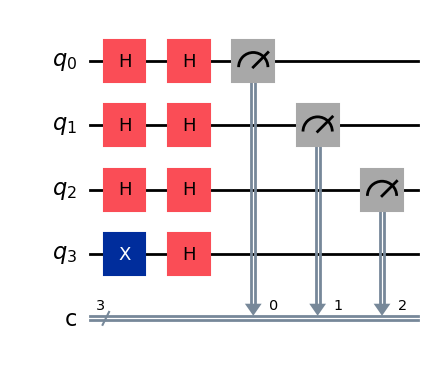

In [6]:
# Parameters
n_qubits = 3  # Number of input qubits

# Create circuits with constant and balanced oracles
constant_oracle = create_oracle(n_qubits, 'constant', 0)
constant_circuit = deutsch_jozsa_circuit(n_qubits, constant_oracle)
constant_circuit.draw('mpl')

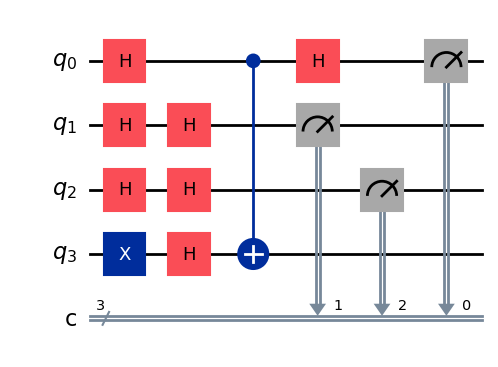

In [7]:
balanced_oracle = create_oracle(n_qubits, 'balanced')
balanced_circuit = deutsch_jozsa_circuit(n_qubits, balanced_oracle)
balanced_circuit.draw('mpl')

In [8]:
# First, run on simulator for comparison
simulator = AerSimulator()
constant_sim_job = simulator.run(constant_circuit, shots=1000)
balanced_sim_job = simulator.run(balanced_circuit, shots=1000)

print("Simulator Results:")
print("Constant function:", constant_sim_job.result().get_counts())
print("Balanced function:", balanced_sim_job.result().get_counts())

Simulator Results:
Constant function: {'000': 1000}
Balanced function: {'001': 1000}


In [9]:
# Now set up for running on IBM Quantum
# Replace 'YOUR_API_TOKEN' with your IBM Quantum API token
#service = QiskitRuntimeService(
#    channel="ibm_quantum",
#    token="YOUR_API_TOKEN"
#)

service = QiskitRuntimeService()

# List all available backends and their status
print("\nAvailable backends and their status:")
for backend in service.backends():
    status = backend.status()
    print(f"{backend.name}:")
    print(f"  - Operational: {status.operational}")
    print(f"  - Pending jobs: {status.pending_jobs}")
    print(f"  - Number of qubits: {backend.num_qubits}")

# Get the least busy backend
try:
    backend_name = get_least_busy_backend(service, min_qubits=n_qubits + 1)
    print(f"\nSelected least busy backend: {backend_name}")
except ValueError as e:
    print(f"Error: {e}")
    exit(1)
    
# Get the backend instance
backend = service.backend(backend_name)

# Create a pass manager with optimization level 1
pass_manager = generate_preset_pass_manager(
    optimization_level=3,
    target=backend.target
)

# Transpile the circuits
print("\nTranspiling circuits...")
transpiled_constant_circuit = pass_manager.run(constant_circuit)
transpiled_balanced_circuit = pass_manager.run(balanced_circuit)


Available backends and their status:
ibm_brisbane:
  - Operational: True
  - Pending jobs: 36
  - Number of qubits: 127
ibm_sherbrooke:
  - Operational: True
  - Pending jobs: 240
  - Number of qubits: 127
ibm_kyiv:
  - Operational: True
  - Pending jobs: 231
  - Number of qubits: 127

Selected least busy backend: ibm_brisbane

Transpiling circuits...


In [10]:
print(f"Original constant circuit depth: {constant_circuit.depth()}")
print(f"Transpiled constant circuit depth: {transpiled_constant_circuit.depth()}")
print(f"Original balanced circuit depth: {balanced_circuit.depth()}")
print(f"Transpiled balanced circuit depth: {transpiled_balanced_circuit.depth()}")

Original constant circuit depth: 3
Transpiled constant circuit depth: 3
Original balanced circuit depth: 5
Transpiled balanced circuit depth: 12


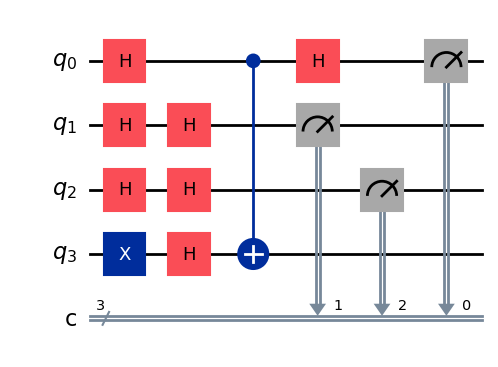

In [11]:
balanced_circuit.draw("mpl")

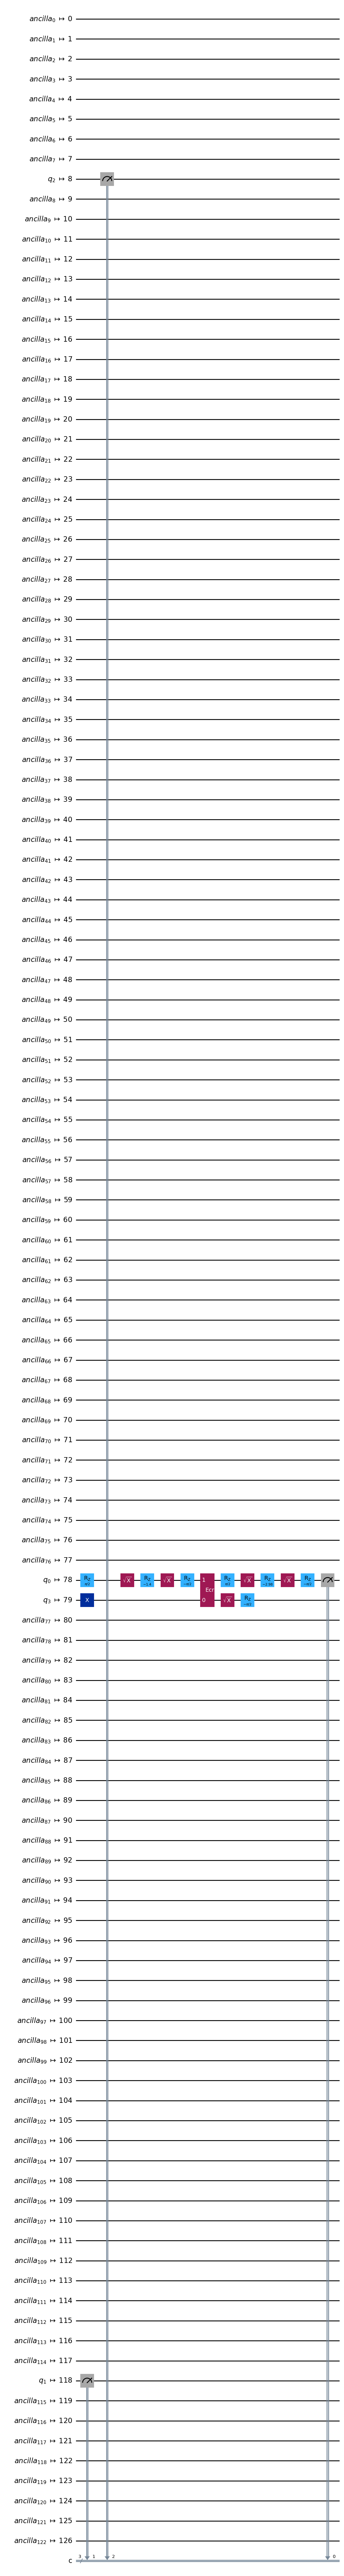

In [12]:
transpiled_balanced_circuit.draw("mpl")

In [ ]:
# Create a session
with Session(backend=backend) as session:
    print(f"\nStarting session on {backend_name}")
    
    # Create a Sampler primitive
    sampler = Sampler()
    sampler.options.default_shots = 1024

    
    print("Submitting batch job...")
    job = sampler.run([transpiled_constant_circuit, transpiled_balanced_circuit])
    
    # Wait for the job to complete and get results
    print("Waiting for job completion...")
    result = job.result()
   
    # Process and print results
    constant_counts = result.quasi_dists[0]
    balanced_counts = result.quasi_dists[1]
    
    print("\nIBM Quantum Results:")
    print("Constant function:", constant_counts)
    print("Balanced function:", balanced_counts)

In [ ]:
def interpret_results(counts):
    # If we measure all zeros, the function is constant
    # Otherwise, it's balanced
    all_zeros = '0' * n_qubits
    print(all_zeros)
    is_constant = all_zeros in counts and counts[all_zeros] > 0.9
    return "Constant" if is_constant else "Balanced"

In [ ]:
print("\nInterpretation of IBM Quantum results:")
print("Constant function:", interpret_results(constant_counts))
print("Balanced function:", interpret_results(balanced_counts))